<h1><font color='blue'>Recomendação Não Personalizada: Rankings</font></h1>


---

## Visão geral

Este notebook faz parte de uma coleção de exercícios desenvolvidos durante minha Pós-Graduação em Inteligência Artificial e Aprendizado de Máquina. O notebook explora fundamentos de sistemas de recomendação, com foco em estratégias não personalizadas que podem gerar sugestões mesmo quando a plataforma ainda não conhece as preferências individuais de uma pessoa.

## Objetivo

O objetivo é principal **consolidar os fundamentos de sistemas de recomendação** por meio da implementação, do zero e com bibliotecas, de estratégias de **recomendação não personalizada** — aquelas que não dependem do histórico individual do usuário e são essenciais para resolver o problema de **cold start**, quando o sistema ainda não conhece o perfil de quem chega.

## Por que isso importa?

Antes de partir para modelos sofisticados de filtragem colaborativa ou deep learning, é fundamental dominar as técnicas de base: rankings por popularidade, média ponderada (IMDb weighted rating). São elas que sustentam recomendações confiáveis em cenários de dados escassos — competência central para quem projeta sistemas de recomendação reais.

## Abordagens exploradas

### 1. Rankings de filmes

Com dados do MovieLens, o notebook realiza análise exploratória das avaliações e constrói listas Top-10 utilizando diferentes critérios:
- Popularidade: quantidade de avaliações recebidas por filme.
- Avaliação média: ordenação pela nota média observada.
- Filtro mínimo de votos: redução do efeito de filmes com poucas avaliações.
- Classificação ponderada (IMDb Weighted Rating): combinação da nota média do filme com o número de votos e a média global, equilibrando qualidade observada e volume de avaliações.
A prática evidencia que ordenar apenas pela média pode favorecer filmes com poucas avaliações. A classificação ponderada busca tornar o ranking mais robusto, sem eliminar a necessidade de escolher critérios adequados ao contexto.


# Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Sistema de Recomendação - Conceitos

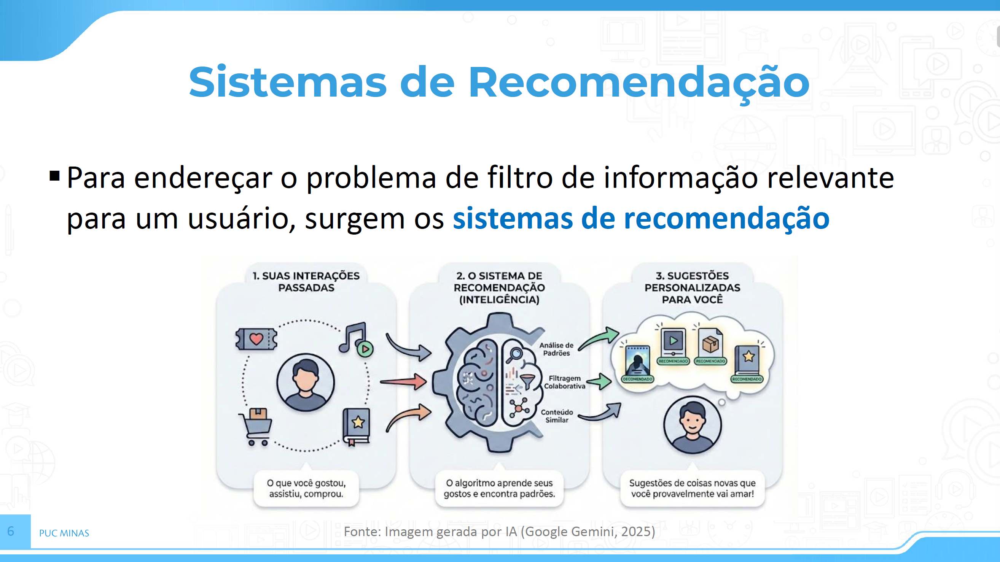

In [2]:
Image('./imagens/aula_03_000.png')

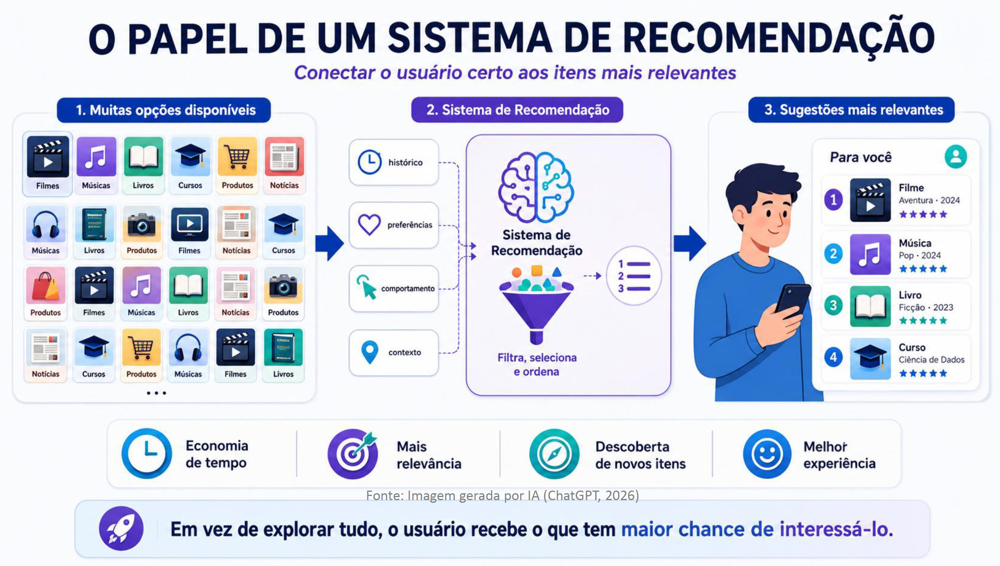

In [3]:
Image('./imagens/aula_03_001.png')

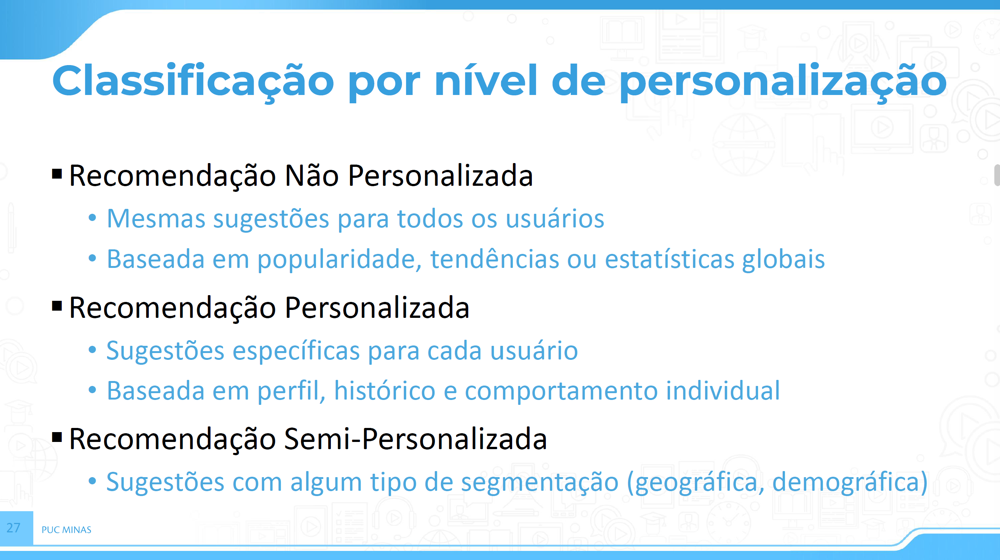

In [4]:
Image('./imagens/aula_03_002.png')

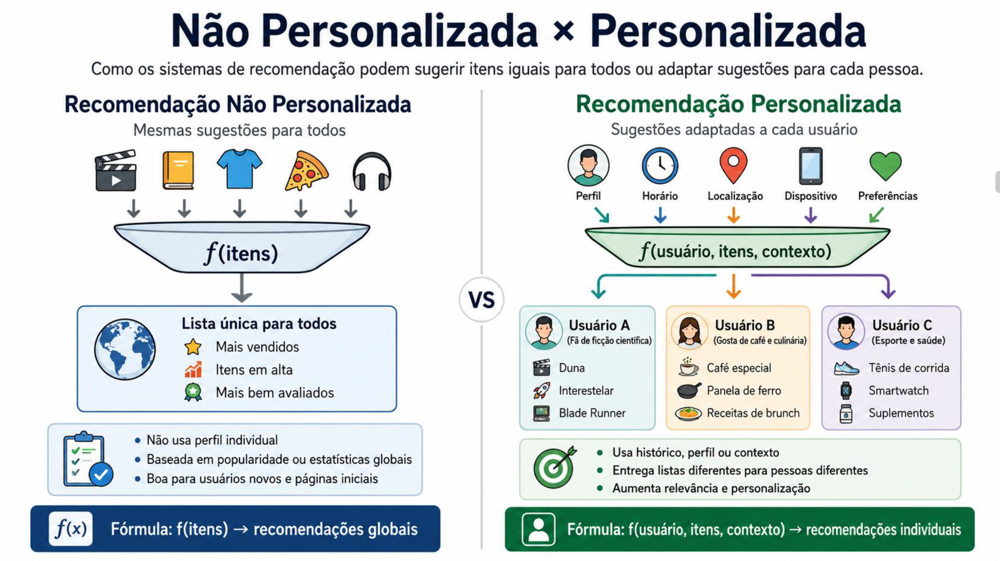

In [5]:
Image('./imagens/aula_03_003.png')

## Movie Lens - Recomendação não personalizada - Listas Top-10 

### Conjunto de dados **MovieLens**

Existem diversos conjuntos de dados disponíveis para pesquisa em sistemas de recomendação. Dentre eles, o conjunto de dados **MovieLens** é provavelmente um dos mais populares.

Os dados do dataset **MovieLens** foram coletados de um sistema de recomendação de filmes não comercial disponível na web no endereço [MovieLens](https://movielens.org/), que foi criado em 1997 e administrado pelo GroupLens, um laboratório de pesquisa da Universidade de Minnesota, a fim de coletar dados de classificação de filmes para fins de pesquisa.



Os arquivos de dados **MovieLens** podem ser encontrados no site [GroupLens](https://grouplens.org/datasets/movielens/).

### Carga de dados

In [6]:
# dataset com as informação dos filmes
movies = pd.read_csv('./datasets/movie_lens_latest_small/movies.csv', header=0, encoding='latin-1', low_memory=False)
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [7]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 626.9 KB


###Arquivo de classificações (*ratings*)

In [8]:
# dataset com as informação das notas dos filmes
ratings = pd.read_csv('./datasets/movie_lens_latest_small/ratings.csv', header=0, encoding='latin-1', low_memory=False)
ratings['timestamp'] = pd.to_datetime(ratings['timestamp'], unit='s')
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0000,2000-07-30 18:45:03
1,1,3,4.0000,2000-07-30 18:20:47
2,1,6,4.0000,2000-07-30 18:37:04
3,1,47,5.0000,2000-07-30 19:03:35
4,1,50,5.0000,2000-07-30 18:48:51


In [9]:
ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype        
---  ------     --------------   -----        
 0   userId     100836 non-null  int64        
 1   movieId    100836 non-null  int64        
 2   rating     100836 non-null  float64      
 3   timestamp  100836 non-null  datetime64[s]
dtypes: datetime64[s](1), float64(1), int64(2)
memory usage: 3.1 MB


### Análise exploratória de dados

###Estatísticas

In [10]:
print(f"Filmes: {movies['movieId'].nunique()}")
print(f"Usuários: {ratings['userId'].nunique()}")
print(f"Avaliações: {len(ratings)}")
print(f"Filmes avaliados: {ratings['movieId'].nunique()}")
print(f"Nota (avaliação): {ratings['rating'].min()} a {ratings['rating'].max()}")

Filmes: 9742
Usuários: 610
Avaliações: 100836
Filmes avaliados: 9724
Nota (avaliação): 0.5 a 5.0


#### Distribuição das notas

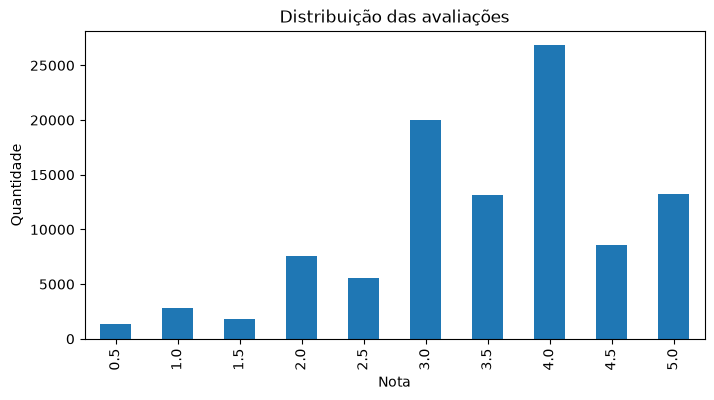

In [11]:
rating_distribution = ratings["rating"].value_counts().sort_index()
rating_distribution.plot(kind="bar", figsize=(8,4))
plt.title("Distribuição das avaliações")
plt.xlabel("Nota")
plt.ylabel("Quantidade")
plt.show()

###Descobrir o total de votos e de classificações por filme

In [12]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0000,2000-07-30 18:45:03
1,1,3,4.0000,2000-07-30 18:20:47
2,1,6,4.0000,2000-07-30 18:37:04
3,1,47,5.0000,2000-07-30 19:03:35
4,1,50,5.0000,2000-07-30 18:48:51


In [13]:
movrat = ratings.groupby('movieId').agg(vote_count=('rating', 'count'), vote_average=('rating', 'mean'))
movrat.head()

,vote_count,vote_average
movieId,,
1,215,3.9209
2,110,3.4318
3,52,3.2596
4,7,2.3571
5,49,3.0714


Incorporar as features de classificação

In [14]:
movies.set_index('movieId', inplace=True)
movies = movies.merge(movrat, how='left', left_index=True, right_index=True)
movies["vote_count"] = movies["vote_count"].fillna(0).astype(int)
movies["vote_average"] = movies["vote_average"].fillna(0)
movies.head()

,title,genres,vote_count,vote_average
movieId,,,,
1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,215,3.9209
2,Jumanji (1995),Adventure|Children|Fantasy,110,3.4318
3,Grumpier Old Men (1995),Comedy|Romance,52,3.2596
4,Waiting to Exhale (1995),Comedy|Drama|Romance,7,2.3571
5,Father of the Bride Part II (1995),Comedy,49,3.0714


### Recomendação simples

Imagine que uma pessoa acabou de entrar em uma plataforma de *streaming* e o sistema ainda não conhece seu histórico.

O que ainda podemos recomendar?

1. filmes mais populares;
2. filmes mais bem avaliados;
3. filmes com melhor equilíbrio entre popularidade e avaliação.

Essas estratégias são exemplos de **recomendação não personalizada**.

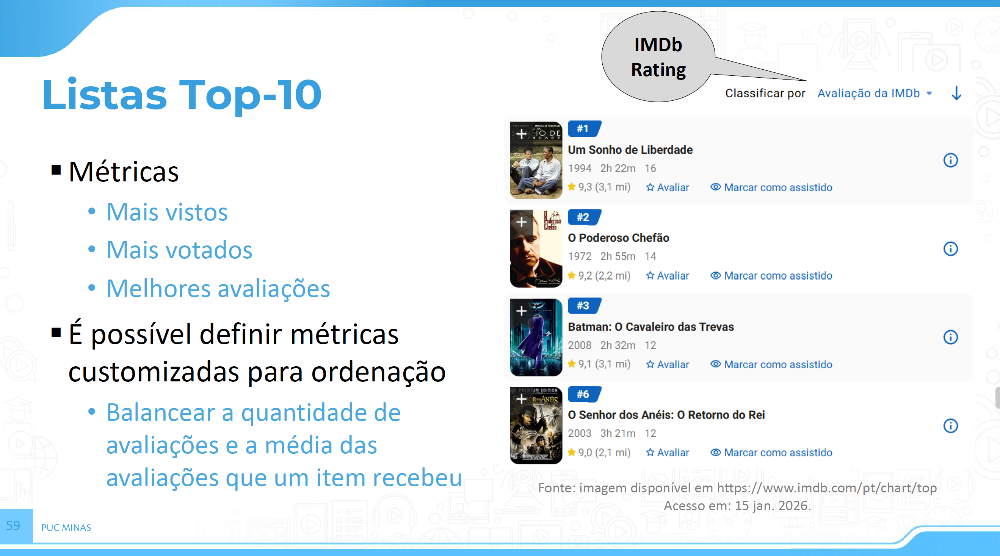

In [15]:
Image('./imagens/aula_03_007.png')

###Top-10 filmes mais votados

In [16]:
top_popularity = ( movies.sort_values(['vote_count','vote_average'],ascending=[False,False])[['title','genres','vote_count','vote_average']].head(10) )
top_popularity

,title,genres,vote_count,vote_average
movieId,,,,
356,Forrest Gump (1994),Comedy|Drama|Romance|War,329,4.1641
318,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.4290
296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,4.1971
593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,279,4.1613
2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278,4.1924
260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251,4.2311
480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,238,3.7500
110,Braveheart (1995),Action|Drama|War,237,4.0316
589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,224,3.9710


###Top-10 filmes melhores classificados

In [17]:
top_average = ( movies.sort_values(['vote_average','vote_count'],ascending=[False,False])[['title','genres','vote_count','vote_average']].head(10) )
top_average

,title,genres,vote_count,vote_average
movieId,,,,
53,Lamerica (1994),Adventure|Drama,2,5.0000
99,Heidi Fleiss: Hollywood Madam (1995),Documentary,2,5.0000
1151,Lesson Faust (1994),Animation|Comedy|Drama|Fantasy,2,5.0000
3473,Jonah Who Will Be 25 in the Year 2000 (Jonas q...,Comedy,2,5.0000
6442,Belle Ã©poque (1992),Comedy|Romance,2,5.0000
6818,Come and See (Idi i smotri) (1985),Drama|War,2,5.0000
78836,Enter the Void (2009),Drama,2,5.0000
148,"Awfully Big Adventure, An (1995)",Drama,1,5.0000
467,Live Nude Girls (1995),Comedy,1,5.0000


**Atenção**:

Observe acima que os filmes com maior classificação tiveram ***poucas avaliações***.



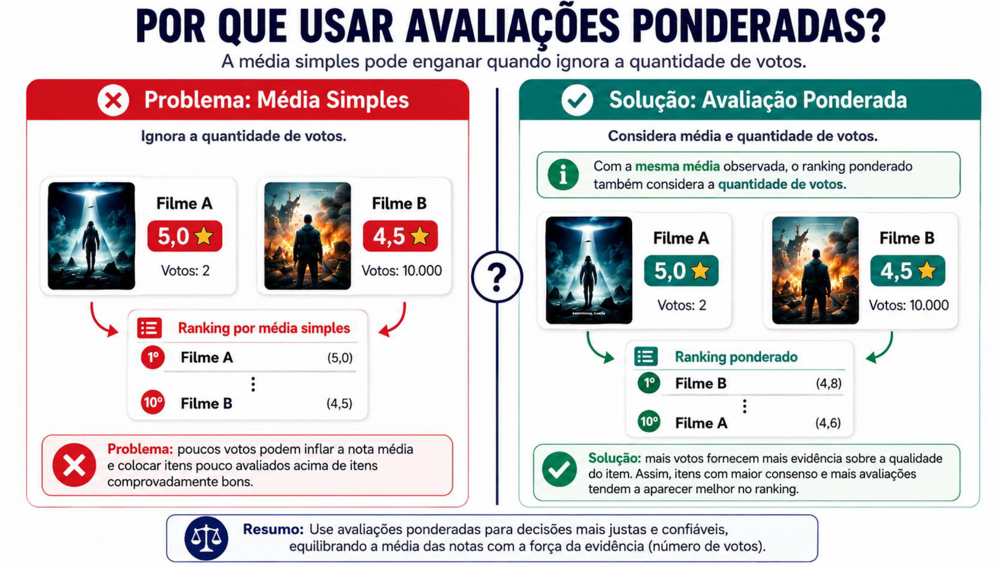

In [18]:
Image('./imagens/aula_03_008.png')

#### Top-10 filmes melhores classificados (pelo menos 20 votos)

Filtrar filmes com pelo menos 20 votos

**Atenção**:

* Observe que existem ainda algumas pequenas variações entre o total de classificações

In [19]:
top_average_min_votes = ( movies[movies['vote_count']>=20].sort_values(['vote_average','vote_count'],ascending=[False,False])[['title','genres','vote_count','vote_average']].head(10) )
top_average_min_votes

,title,genres,vote_count,vote_average
movieId,,,,
1104,"Streetcar Named Desire, A (1951)",Drama,20,4.4750
318,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.4290
922,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Drama|Film-Noir|Romance,27,4.3333
898,"Philadelphia Story, The (1940)",Comedy|Drama|Romance,29,4.3103
1204,Lawrence of Arabia (1962),Adventure|Drama|War,45,4.3000
475,In the Name of the Father (1993),Drama,25,4.3000
246,Hoop Dreams (1994),Documentary,29,4.2931
858,"Godfather, The (1972)",Crime|Drama,192,4.2891
1235,Harold and Maude (1971),Comedy|Drama|Romance,26,4.2885


###Top-10 filmes melhores classificados (classificação balanceada)

Para amenizar estas situações, o [IMDb](https://www.imdb.com/chart/top/?ref_=nv_mv_250) utiliza uma classificação ponderada para balancear o total de votos e a classificação, como pode ser visto na fórmula abaixo:
<br><br>

$$Weighted Rating = \left( \frac{v}{v+m} \right) \times R +  \left( \frac{m}{v+m} \right) \times C$$

Onde,

* $R$ = classificação média do filme (`vote_average`)

* $v$ = número de votos do filme (`vote_count`)

* $m$ = número mínimo de votos a considerar

* $C$ = classificação média de todos os filmes


Se o mínimo a ser considerado $m$ for zero, o valor será exatamente a classificação média do filme $R$.

Para o número mínimo de votos a considerar, variável $m$, geralmente é utilizado o percentil 75, que considera o mínimo de votos dos ***25% dos filmes mais votados***.

O percentil de 75% é utilizado aqui como um dos critérios e não como regra universal.  
O limiar adequado depende do domínio, escala do catálogo e objetivo do sistema.

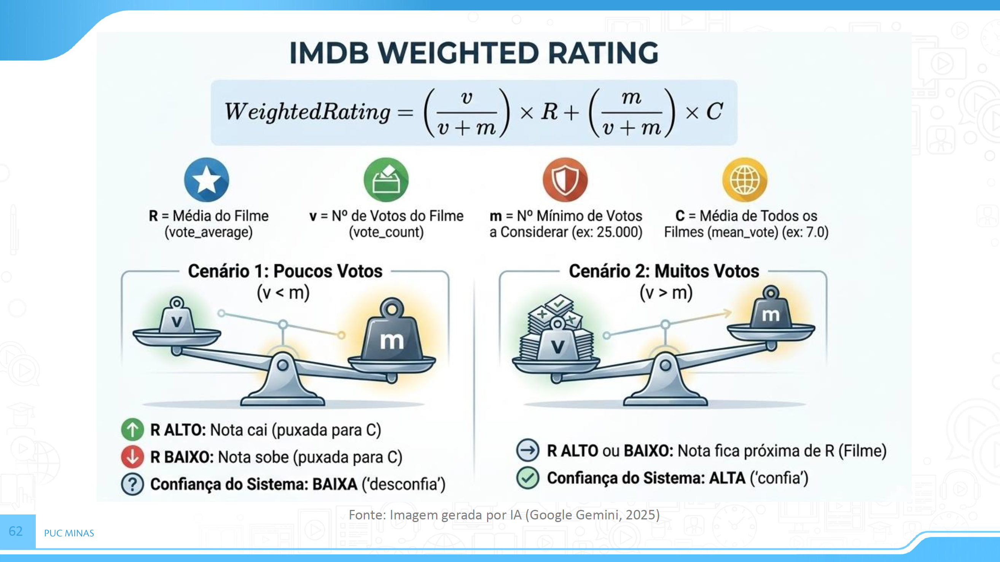

In [20]:
Image('./imagens/aula_03_010.png')

In [21]:
# Pegar a quantidade mínima de votos dos filmes com mais votos que 75% dos filmes

m = movies['vote_count'].quantile(0.75)
m

np.float64(9.0)

In [22]:
print('Total:',movies.shape[0])
print('75%:',movies[ movies['vote_count'] < m].shape[0])
print('25%:',movies[ movies['vote_count'] >= m].shape[0])

Total: 9742
75%: 7301
25%: 2441


Computar a classificação média geral de todos os filmes, variável $C$

In [23]:
# Calcular a avaliação média geral

C = ratings["rating"].mean()
print(f"C = {C:.4f}")

C = 3.5016


A média global é calculada sobre as **avaliações observadas**.  


Calcular o ***IMDb weighted rating*** e armazenar em uma nova coluna `imdb_score`

In [24]:
# Calcular o 'IMDB weighted rating' para cada filme

import math

MIN_RATING = 0.0
MAX_RATING = float(math.ceil(ratings.rating.max()))

print(MIN_RATING, MAX_RATING)

def weighted_rating(x, m=m, C=C):
    v = x['vote_count']
    R = x['vote_average']

    # Compute the weighted score
    return ((v/(v+m)) * R) + ((m/(m+v)) * C)

movies['imdb_score'] = movies.apply(weighted_rating, axis=1)

0.0 5.0


In [25]:
movies.head()

,title,genres,vote_count,vote_average,imdb_score
movieId,,,,,
1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,215,3.9209,3.9041
2,Jumanji (1995),Adventure|Children|Fantasy,110,3.4318,3.4371
3,Grumpier Old Men (1995),Comedy|Romance,52,3.2596,3.2953
4,Waiting to Exhale (1995),Comedy|Drama|Romance,7,2.3571,3.0009
5,Father of the Bride Part II (1995),Comedy,49,3.0714,3.1382


#### Ordenação dos melhores avaliados pelo IMDB score

**Atenção**:

Observe como o novo `imdb_score` equilibra a classificação com o total de votos

In [26]:
top_weighted = (
    movies
    .sort_values(["imdb_score", "vote_count"], ascending=[False, False])
    [["title", "genres", "vote_count", "vote_average", "imdb_score"]]
    .head(10)
)

top_weighted

,title,genres,vote_count,vote_average,imdb_score
movieId,,,,,
318,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.4290,4.4034
858,"Godfather, The (1972)",Crime|Drama,192,4.2891,4.2538
2959,Fight Club (1999),Action|Crime|Drama|Thriller,218,4.2729,4.2424
1221,"Godfather: Part II, The (1974)",Crime|Drama,129,4.2597,4.2102
50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,204,4.2377,4.2066
260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251,4.2311,4.2058
750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,97,4.2680,4.2030
1213,Goodfellas (1990),Crime|Drama,126,4.2500,4.2001
527,Schindler's List (1993),Drama|War,220,4.2250,4.1966
